# Tweedie GLMs

Notes on Tweedie distributions and GLMs based on Chapter 12 of [Generalized Linear Models With Examples in R by Dunn and Smyth](https://www.academia.edu/37886943/Springer_Texts_in_Statistics_Generalized_Linear_Models_With_Examples_in_R)

## Set up

### Imports

In [14]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from glum import GeneralizedLinearRegressor, TweedieDistribution

### Defaults

In [15]:
sns.set_theme(style="whitegrid")

### Constants

In [ ]:
QUILPIE_PATH = "/home/coder/python-playground/data/quilpie.csv"

## Load data

In [ ]:
quilpie = pd.read_csv(QUILPIE_PATH)
quilpie['Phase'] = quilpie['Phase'].astype('category')

## 12.2 The Tweedie EDMs

### 12.2.1 Introducing Tweedie Distributions

**Definition:** An EDM (Exponential Dispersion Model) is a distribution with probability function

\begin{align*}
P(y;\, \theta, \phi) = a(y, \phi) \exp\!\left\{\frac{y\theta - \kappa(\theta)}{\phi}\right\}
\end{align*}

where $\theta$ is the **canonical parameter**, $\kappa(\theta)$ is the **cumulant function**, $\phi > 0$ is the **dispersion parameter**, and $a(y,\phi)$ is a normalizing function.
The mean $\mu$ is a known function of $\theta$.
Written $y \sim \text{EDM}(\mu, \phi)$.

Examples: normal, gamma (continuous); Poisson, binomial, negative binomial (discrete).

**Definition:** Any EDM with a variance function $V(\mu) = \mu^{\xi}$ is called a Tweedie distribution, or a Tweedie EDM, where $\xi$ can take any real value except $0<\xi<1$.
$\xi$ is called the *Tweedie index parameter* and is sometimes denoted by *p*.

The full variance is $\text{Var}(Y) = \phi \cdot V(\mu) = \phi \mu^\xi$.
$V(\mu) = \mu^\xi$ is the variance *function* — only the $\mu$-dependent part.

Tweedie distributions fall into four categories, depending on $\xi$:

- **$\xi \leq 0$**: Continuous data on $(-\infty, \infty)$.
The normal distribution ($\xi = 0$) is the key special case — $\xi<0$ has no realistic applications.

- **$\xi = 1$**: Discrete data where $y = 0, \phi, 2\phi, 3\phi, \ldots$.
The Poisson distribution is the special case when $\phi = 1$.

- **$1 < \xi < 2$**: Positive continuous data with a point mass at zero.
These are compound Poisson-Gamma distributions.

- **$\xi \geq 2$**: Positive continuous data ($y > 0$).
Gamma ($\xi = 2$) and inverse Gaussian ($\xi = 3$) are special cases.
The distributions become more right-skewed as $\xi$ increases.

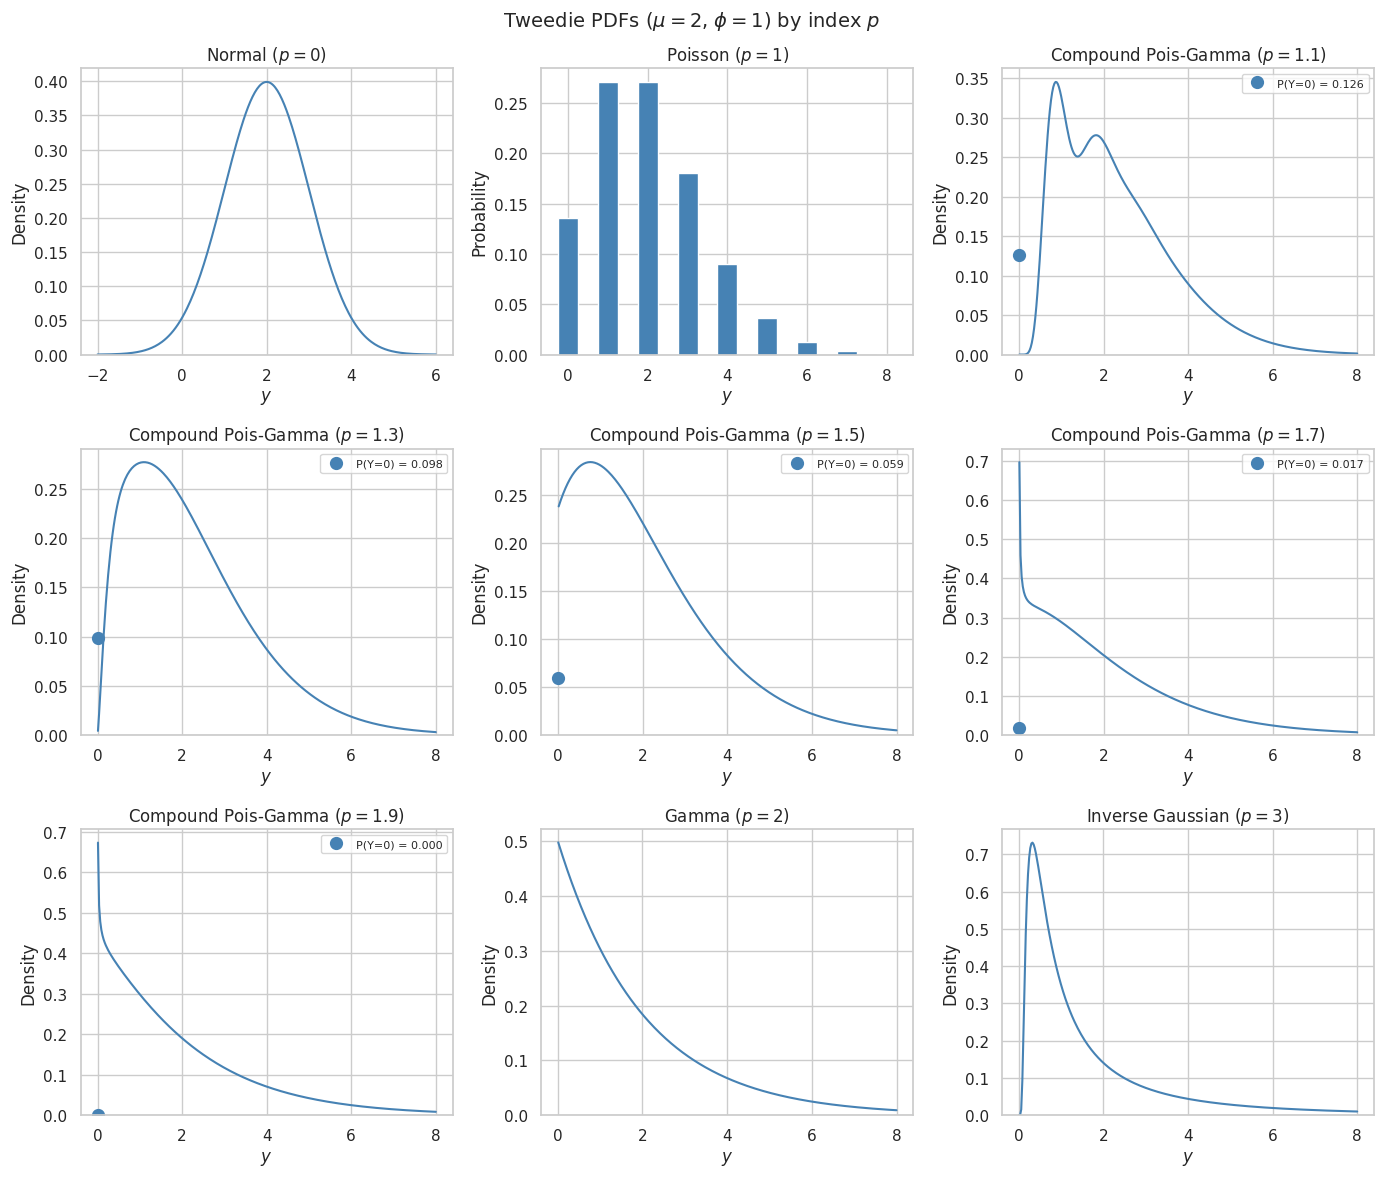

In [21]:
mu = 2.0
phi = 1.0

# glum log_likelihood only supports p in {0, 1, (1,2), 2, 3}
configs = [
    (0,   "Normal ($p=0$)",               np.linspace(-2, 6, 300)),
    (1,   "Poisson ($p=1$)",              np.arange(0, 9)),
    (1.1, "Compound Pois-Gamma ($p=1.1$)", np.linspace(0.01, 8, 300)),
    (1.3, "Compound Pois-Gamma ($p=1.3$)", np.linspace(0.01, 8, 300)),
    (1.5, "Compound Pois-Gamma ($p=1.5$)", np.linspace(0.01, 8, 300)),
    (1.7, "Compound Pois-Gamma ($p=1.7$)", np.linspace(0.01, 8, 300)),
    (1.9, "Compound Pois-Gamma ($p=1.9$)", np.linspace(0.01, 8, 300)),
    (2,   "Gamma ($p=2$)",                np.linspace(0.01, 8, 300)),
    (3,   "Inverse Gaussian ($p=3$)",     np.linspace(0.01, 8, 300)),
]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
fig.suptitle(r"Tweedie PDFs ($\mu=2$, $\phi=1$) by index $p$", fontsize=14)

for ax, (p, title, y_grid) in zip(axes.flat, configs):
    dist = TweedieDistribution(power=p)
    pmf = np.exp([dist.log_likelihood(y, mu, dispersion=phi) for y in y_grid])

    if p == 1:
        ax.bar(y_grid, pmf, color="steelblue", width=0.5)
        ax.set_ylabel("Probability")
    else:
        ax.plot(y_grid, pmf, color="steelblue", linewidth=1.5)
        ax.set_ylabel("Density")

    if 1 < p < 2:
        p0 = float(np.exp(dist.log_likelihood(0.0, mu, dispersion=phi)))
        ax.plot(0, p0, "o", color="steelblue", markersize=8,
                markeredgewidth=1.5, label=f"P(Y=0) = {p0:.3f}")
        ax.legend(fontsize=8)

    ax.set_title(title)
    ax.set_xlabel("$y$")
    ax.set_ylim(bottom=0)

for ax in axes.flat[len(configs):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 12.2.2 The Structure of Tweedie EDMs

Given $V(\mu) = \mu^\xi$, the canonical parameter and cumulant function are:

\begin{align*}
\theta = \begin{cases} \dfrac{\mu^{1-\xi}}{1-\xi} & \xi \neq 1 \\[6pt] \log \mu & \xi = 1 \end{cases} \qquad \kappa(\theta) = \begin{cases} \dfrac{\mu^{2-\xi}}{2-\xi} & \xi \neq 2 \\[6pt] \log \mu & \xi = 2 \end{cases}
\end{align*}

Given $\xi$, the distribution is fully determined by $\mu$, $\phi$, and $\xi$ — written $y \sim \text{Tw}_\xi(\mu, \phi)$.
The dispersion parameter $\phi$ scales the variance: $\text{Var}(Y) = \phi\mu^\xi$.

No closed form exists for the normalizing constant $a(y, \phi)$ except in the four special cases ($\xi \in \{0, 1, 2, 3\}$); in general, numerical methods are required to evaluate the density.

**Deviance.** The deviance measures how well a fitted model explains the data relative to the *saturated model* — a model with one parameter per observation that fits the data exactly.
It is defined as twice the log-likelihood ratio between the two:

\begin{align*}
D(y, \hat{\mu}) = 2\left[\ell(\hat{\theta}_s; y) - \ell(\hat{\theta}_0; y)\right]
\end{align*}

where $\hat{\theta}_s$ are the saturated model parameters and $\hat{\theta}_0$ are those of the fitted model.
The deviance is a generalization of the idea of using the sum of squares of residuals (SSR) in ordinary least squares to cases where model-fitting is achieved by maximum likelihood.

The unit deviance for the Tweedie EDM is:

\begin{align*}
d(y, \mu) = \begin{cases} 2\left[\dfrac{\max(y,0)^{2-\xi}}{(1-\xi)(2-\xi)} - \dfrac{y\mu^{1-\xi}}{1-\xi} + \dfrac{\mu^{2-\xi}}{2-\xi}\right] & \xi \neq 1, 2 \\[10pt] 2\left[y\log\dfrac{y}{\mu} - (y - \mu)\right] & \xi = 1 \\[10pt] 2\left[-\log\dfrac{y}{\mu} + \dfrac{y-\mu}{\mu}\right] & \xi = 2 \end{cases}
\end{align*}

**Rescaling identity.** Writing $P_\xi(y;\, \mu,\, \phi)$ for the probability function of $\text{Tw}_\xi(\mu, \phi)$, for $y > 0$ and $c > 0$:

\begin{align*}
P_\xi(y;\, \mu,\, \phi) = c \cdot P_\xi(cy;\, c\mu,\, c^{2-\xi}\phi)
\end{align*}

This says that multiplying the data by $c$ (a change of units) is equivalent to scaling $\mu$ by $c$ and $\phi$ by $c^{2-\xi}$ — the shape of the distribution is preserved.

### 12.2.3 Tweedie EDMs for Positive Continuous Data

Generally, for positive continuous data, the Gamma and Inverse Gaussian distributions are sufficient, but sometimes for extremely skewed data, a Tweedie with $\xi\geq 2$ can be more appropriate.

### 12.2.4 Tweedie EDMs for Positive Continuous Data with Exact Zeros

Let $N \sim \text{Pois}(\lambda^*)$ and, independently, $z_1, z_2, \ldots \sim \text{Gam}(\mu^*, \phi^*)$ i.i.d.
Define $y = \sum_{i=1}^N z_i$ (with $y = 0$ when $N = 0$).
Then $y \sim \text{Tw}_\xi(\mu, \phi)$ for some $1 < \xi < 2$, with the parameters related by:

\begin{align*}
\lambda^* &= \frac{\mu^{2-\xi}}{\phi(2-\xi)} \\[6pt]
\mu^* &= (2-\xi)\phi\mu^{\xi-1} \\[6pt]
\phi^* &= (2-\xi)(\xi-1)\phi^2\mu^{2(\xi-1)}
\end{align*}

Since $N$ may be zero, $y$ has a point mass at zero with probability:

\begin{align*}
\pi_0 = \Pr(y = 0) = \exp(-\lambda^*) = \exp\!\left(-\frac{\mu^{2-\xi}}{\phi(2-\xi)}\right)
\end{align*}

## 12.3 Tweedie GLMs

**Quilpie rainfall data** — 68 observations of total July rainfall in Quilpie, Australia.

| Variable | Description |
|----------|-------------|
| `Year` | Year of observation |
| `Rain` | Total July rainfall (mm) |
| `SOI` | July average Southern Oscillation Index |
| `Phase` | SOI phase: 1 = consistently negative, 2 = consistently positive, 3 = rapidly falling, 4 = rapidly rising, 5 = consistently near zero |
| `Exceed` | Whether rainfall exceeds 10mm (`Yes`/`No`) |
| `y` | Same as `Exceed` coded as 1/0 |

### 12.3.1 Introduction

Tweedie GLMs are specified as $\text{glm}(\text{Tw}_\xi;\, \text{link function})$.
Since $\mu > 0$ for all Tweedie cases considered here, the log link is standard.
$\phi$ is typically estimated using the Pearson estimator, though the MLE of $\phi$ is needed if computing $\hat{\pi}_0$ (the probability of an exact zero).

### 12.3.2 Estimating $\xi$

Fitting a Tweedie GLM requires the value of $\xi$ to be known.
Since $\hat{\xi}$ and $\hat{\beta}$ are nearly uncorrelated, using an estimated $\hat{\xi}$ has little effect on inference about $\beta$.
Since exact zeros are present in the Quilpie data, we know $1 < \xi < 2$.

Two approaches are used to estimate $\xi$.

**Method 1: Group-based estimate.**
Since $\text{Var}(Y) = \phi\mu^\xi$, taking logs gives $\log\text{Var}(Y) = \log\phi + \xi\log\mu$.
So $\xi$ can be estimated as the slope of $\log(\text{group variance})$ against $\log(\text{group mean})$.
This is done for two groupings: by SOI phase and by decade.
The estimates will differ since they depend on how data are grouped.

In [ ]:
quilpie['Decade'] = pd.cut(quilpie['Year'], bins=range(1920, 1991, 10))

# Group by SOI Phase
mn_phase = quilpie.groupby('Phase')['Rain'].mean()
vr_phase = quilpie.groupby('Phase')['Rain'].var()
slope_phase, intercept_phase, *_ = stats.linregress(np.log(mn_phase), np.log(vr_phase))

# Group by Decade
mn_dec = quilpie.groupby('Decade', observed=True)['Rain'].mean()
vr_dec = quilpie.groupby('Decade', observed=True)['Rain'].var()
slope_dec, intercept_dec, *_ = stats.linregress(np.log(mn_dec), np.log(vr_dec))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Method 1: estimating $\xi$ from group log(variance) vs log(mean)")

for ax, (mn, vr, slope, intercept, title) in zip(axes, [
    (mn_phase, vr_phase, slope_phase, intercept_phase, "By SOI Phase"),
    (mn_dec,   vr_dec,   slope_dec,   intercept_dec,   "By Decade"),
]):
    ax.scatter(np.log(mn), np.log(vr), color="steelblue", zorder=3)
    x_line = np.linspace(np.log(mn).min(), np.log(mn).max(), 100)
    ax.plot(x_line, intercept + slope * x_line, color="salmon")
    ax.set_xlabel(r"$\log(\bar{y})$")
    ax.set_ylabel(r"$\log(s^2)$")
    ax.set_title(f"{title} — slope $\\hat{{\\xi}}$ = {slope:.2f}")

plt.tight_layout()
plt.show()

pd.DataFrame({
    "Grouping": ["By SOI Phase", "By Decade"],
    "xi estimate": [slope_phase, slope_dec],
    "Book value":  [1.553, 1.946],
}).set_index("Grouping").round(4)

Both estimates satisfy $1 \leq \hat{\xi} \leq 2$, consistent with the presence of exact zeros.
However, the two estimates differ substantially (1.55 vs 1.95), illustrating the sensitivity of this approach to the choice of grouping.

**Method 2: Profile likelihood.**
A more rigorous approach that uses the explanatory variables directly.
For each candidate $\xi$, the Tweedie GLM is fitted and the log-likelihood recorded.
The profile likelihood estimate $\hat{\xi}$ maximises this.
A 95% CI uses the result that $2[\ell(\hat{\xi}) - \ell(\xi)] \sim \chi^2_1$, so the CI is the region where $\ell(\xi) \geq \ell(\hat{\xi}) - \chi^2_{1,0.95}/2$.

A known pitfall: if the data are rounded to few decimal places, the likelihood can be maximised near $\xi = 1$ with $\phi$ matching the rounding precision — a spurious result to watch for in the profile plot.

In [ ]:
X = quilpie[['Phase']]
y = quilpie['Rain'].values

xi_vec = np.linspace(1.01, 1.99, 200)
ll_vec = []

for xi in xi_vec:
    dist = TweedieDistribution(power=xi)
    model = GeneralizedLinearRegressor(
        family=dist, link='log', alpha=0,
        fit_intercept=True, drop_first=True
    )
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        try:
            model.fit(X, y)
            mu_hat = model.predict(X)
            phi_hat = dist.dispersion(y, mu_hat, ddof=len(model.coef_) + 1)
            ll_vec.append(dist.log_likelihood(y, mu_hat, dispersion=phi_hat))
        except Exception:
            ll_vec.append(np.nan)

ll_vec = np.array(ll_vec)
xi_mle = xi_vec[np.nanargmax(ll_vec)]
ll_max = np.nanmax(ll_vec)

# 95% CI: region where ll > ll_max - chi2(1, 0.95)/2
ci_threshold = ll_max - stats.chi2.ppf(0.95, df=1) / 2
ci_mask = ll_vec >= ci_threshold
xi_ci_lo = xi_vec[np.where(ci_mask)[0][0]]
xi_ci_hi = xi_vec[np.where(ci_mask)[0][-1]]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xi_vec, ll_vec, color="steelblue")
ax.axvline(xi_mle, color="salmon", linestyle="--", label=f"$\\hat{{\\xi}}$ = {xi_mle:.3f}")
ax.axhline(ci_threshold, color="grey", linestyle="--", label="95% CI threshold")
ax.set_xlabel(r"$\xi$")
ax.set_ylabel("Profile log-likelihood")
ax.set_title("Profile likelihood for $\\xi$")
ax.set_ylim(ll_max - 20, ll_max + 1)
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({
    "": ["xi MLE", "95% CI lower", "95% CI upper"],
    "Python": [xi_mle, xi_ci_lo, xi_ci_hi],
    "Book":   [1.37, 1.270, 1.499],
}).set_index("").round(3)

The profile likelihood estimate ($\hat{\xi} \approx 1.41$) is close to the book's value of 1.37; the small difference reflects the different numerical methods used to evaluate the Tweedie density.
The 95% CI is consistent with the book's $[1.27, 1.50]$.

### 12.3.3 Fitting the Tweedie GLM

Using $\hat{\xi}$ from the profile likelihood, fit the Tweedie GLM with `Phase` as predictor and a log link.
The log link is standard for Tweedie GLMs since $\mu > 0$.
$\phi$ is estimated using the Pearson estimator.

In [ ]:
xi_est = round(xi_mle, 2)

dist_fit = TweedieDistribution(power=xi_est)
model_fit = GeneralizedLinearRegressor(
    family=dist_fit, link='log', alpha=0,
    fit_intercept=True, drop_first=True
)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    model_fit.fit(X, y)

mu_hat = model_fit.predict(X)
phi_hat = dist_fit.dispersion(y, mu_hat, ddof=len(model_fit.coef_) + 1)

coef_df = pd.DataFrame({
    "Coefficient": ["Intercept"] + list(model_fit.feature_names_),
    "Estimate":    [model_fit.intercept_] + list(model_fit.coef_),
    "Book":        [-2.1691, 5.6923, 3.5153, 5.0269, 4.6468],
}).set_index("Coefficient").round(4)

display(coef_df)

display(
    pd.DataFrame({'Phase': quilpie['Phase'], 'Fitted mean': mu_hat})
    .groupby('Phase')['Fitted mean'].first()
    .round(4)
)

pd.DataFrame({
    "": ["xi used", "Pearson phi"],
    "Value": [xi_est, round(phi_hat, 4)],
}).set_index("")

The coefficients match the book closely.
Phase 1 (consistently negative SOI) is the reference level with the lowest predicted rainfall ($\hat{\mu}_1 \approx 0.11$ mm).
Phase 2 (consistently positive SOI) has the highest predicted rainfall ($\hat{\mu}_2 \approx 33.9$ mm), consistent with La Niña conditions bringing above-average rainfall to inland Queensland.

**Residual diagnostics.**
For Tweedie GLMs with $1 < \xi < 2$, quantile residuals are strongly preferred over deviance or Pearson residuals.
When exact zeros are present, deviance and Pearson residuals form a visible band in the lower-left of a Q–Q plot, making the plots hard to interpret.
Quantile residuals remove this by randomising the CDF value at $y = 0$: drawing $u \sim \text{Uniform}(0, \pi_0)$ and then applying the normal quantile function $\Phi^{-1}(u)$.
For $y > 0$ the CDF is evaluated directly.
Two realisations are plotted since the randomisation introduces some variability.

In [ ]:
# Deviance residuals: sign(y - mu) * sqrt(d(y, mu) / phi)
d = np.array([dist_fit.unit_deviance(yi, mi) for yi, mi in zip(y, mu_hat)])
dev_resid = np.sign(y - mu_hat) * np.sqrt(d / phi_hat)

# Pearson residuals: (y - mu) / sqrt(phi * mu^xi)
pearson_resid = (y - mu_hat) / np.sqrt(phi_hat * mu_hat**xi_est)

# Quantile residuals via randomisation at y=0 and CDF at y>0
pi0 = np.exp(-mu_hat**(2 - xi_est) / (phi_hat * (2 - xi_est)))

def quantile_resid(seed):
    from tweedie import tweedie as tw_dist
    rng_q = np.random.default_rng(seed)
    qr = np.zeros(len(y))
    for i, (yi, mu_i, pi0_i) in enumerate(zip(y, mu_hat, pi0)):
        if yi == 0:
            u = rng_q.uniform(0, pi0_i)
        else:
            u = np.clip(tw_dist(p=xi_est, mu=mu_i, phi=phi_hat).cdf(yi), 1e-10, 1 - 1e-10)
        qr[i] = stats.norm.ppf(u)
    return qr

qr1 = quantile_resid(42)
qr2 = quantile_resid(99)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
fig.suptitle("Q\u2013Q plots of residuals for Tweedie GLM (Quilpie data)", fontsize=13)

for ax, resid, title in zip(axes.flat,
    [dev_resid, pearson_resid, qr1, qr2],
    ["Deviance residuals", "Pearson residuals",
     "Quantile residuals (set 1)", "Quantile residuals (set 2)"]):
    stats.probplot(resid, plot=ax)
    ax.set_title(title)
    ax.get_lines()[1].set_color("salmon")

plt.tight_layout()
plt.show()

The Q–Q plots confirm the book's observation: deviance and Pearson residuals show a band of points in the lower-left corner corresponding to the exact zeros, making the plots inconclusive.
The quantile residuals follow the normal line much more closely, suggesting the model is adequate.

**Predicted probability of zero rainfall.**
Using the compound Poisson-Gamma parameterisation, $\hat{\pi}_0 = \exp(-\lambda^*)$ where $\lambda^* = \mu^{2-\xi} / (\phi(2-\xi))$.
This gives the model's predicted probability of a dry July for each SOI phase.

In [ ]:
# Predicted pi0 per phase (one value per phase since mu is constant within phase)
pi0_by_phase = (
    pd.DataFrame({'Phase': quilpie['Phase'], 'pi0_hat': pi0})
    .groupby('Phase')['pi0_hat'].first()
)

# Observed proportion of zeros per phase
prop0_by_phase = quilpie.groupby('Phase')['Rain'].apply(lambda x: (x == 0).mean())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(prop0_by_phase, pi0_by_phase, color="steelblue", zorder=3)
ax.plot([0, 1], [0, 1], color="salmon", linestyle="--")
for phase in prop0_by_phase.index:
    ax.annotate(f"Phase {phase}",
                (prop0_by_phase[phase], pi0_by_phase[phase]),
                textcoords="offset points", xytext=(6, 0), fontsize=9)
ax.set_xlabel("Observed proportion of zeros")
ax.set_ylabel(r"Predicted $\hat{\pi}_0$")
ax.set_title(r"Observed vs predicted probability of zero rainfall by SOI phase")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

pd.DataFrame({
    "Observed prop zeros": prop0_by_phase,
    r"Predicted pi0": pi0_by_phase,
}).round(3)

The model predicts the zero-rainfall probabilities with reasonable accuracy.
Note that Phase 2 has no observed zeros in the data, yet the model assigns a small positive probability ($\hat{\pi}_0 \approx 0.11$) — reflecting that a dry July during a consistently positive SOI is possible but unlikely.